# Laboratorio 13 — Exposición a fármacos y laboratorios
**OMOP CDM v5.4: DRUG_EXPOSURE, MEASUREMENT y tablas derivadas (DRUG_ERA, PDC)**

Este notebook usa la base del Lab 12 (`~/s12-omop-cdm-introduccion/omop.duckdb`) y las consultas de `sql/farmacoepi.sql`.

* Las consultas SQL **viven en `sql/farmacoepi.sql`**; aquí las llamamos por su número con `consulta("5.2")` (así el notebook y el script dan exactamente lo mismo).
* Algunas celdas usan la *magia* `%sql` / `%%sql` de **jupysql**.
* Las figuras se guardan también como PNG en `figuras/`.
* Si las tablas `results.*` no existen, la primera celda las crea (equivale a `python sql/correr_farmacoepi.py --crear`).

> ⚠️ DuckDB bloquea el fichero: mientras este notebook esté abierto **no** ejecutes `correr_farmacoepi.py` ni abras la base en DBeaver. Para soltar el bloqueo: *Kernel → Shut Down Kernel*.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

CARPETA = Path.cwd()                      # carpeta del lab 13 (donde está este .ipynb)
sys.path.insert(0, str(CARPETA / "sql"))
import correr_farmacoepi as cf            # reutilizamos el lector de farmacoepi.sql

FIGURAS = CARPETA / "figuras"
FIGURAS.mkdir(exist_ok=True)
print("Base de datos:", cf.DB_PATH)

# 1) Crear las tablas results.* si faltan (abre la base en escritura y la cierra)
with duckdb.connect(str(cf.DB_PATH), read_only=True) as tmp:
    falta = not cf.results_completo(tmp)
if falta:
    print("Creando tablas results.* (solo la primera vez)...")
    cf.crear_results()

# 2) Conexión de SOLO LECTURA para el resto del notebook
con = duckdb.connect(str(cf.DB_PATH), read_only=True)
CONSULTAS = {cid: (preg, sql) for cid, preg, sql in cf.leer_consultas()}

def consulta(cid):
    """Ejecuta la consulta cid de farmacoepi.sql y devuelve un DataFrame.
    En las consultas [CREA ...] solo ejecuta su SELECT final (la tabla ya existe)."""
    preg, sql = CONSULTAS[cid]
    print(f"CONSULTA {cid} | {preg}")
    return cf.ejecutar(con, sql, solo_resumen=preg.startswith("[CREA"))

def guardar(fig, nombre):
    ruta = FIGURAS / nombre
    fig.savefig(ruta, dpi=120, bbox_inches="tight")
    print("Figura guardada en", ruta)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
consulta("0.1")

Base de datos: /home/alecedillo/s12-omop-cdm-introduccion/omop.duckdb
CONSULTA 0.1 | [CREA results.parametros] ¿Qué ingrediente, analitos y ventanas usaremos en todo el lab?


,ingrediente_id,ingrediente,analito_basal_id,analito_basal,glucosa_id,glucosa,ventana_persistencia_dias,seguimiento_pdc_dias,ventana_basal_dias
0,1308216,lisinopril,3004249,Systolic blood pressure,3000483,Glucose [Mass/volume] in Blood,30,365,90


### jupysql
Conectamos la magia `%sql` a la **misma** conexión DuckDB (no hace falta `duckdb-engine` ni SQLAlchemy URL).

In [2]:
%load_ext sql
%config SqlMagic.displaylimit = 25
%sql con --alias omop

## Actividad 1 — ¿Prescripciones, dispensaciones o administraciones?
`drug_type_concept_id` indica la **procedencia** del registro. Nuestro ETL puso 32817 (*EHR*) a todo; `medications.csv` de Synthea son **prescripciones**.

In [3]:
%%sql
SELECT d.drug_type_concept_id,
       COALESCE(c.concept_name, '(no está en CONCEPT)') AS tipo_registro,
       count(*)                    AS n_registros,
       count(DISTINCT d.person_id) AS n_personas
FROM drug_exposure d
LEFT JOIN concept c ON c.concept_id = d.drug_type_concept_id
GROUP BY 1, 2
ORDER BY n_registros DESC

Running query in 'omop'

drug_type_concept_id,tipo_registro,n_registros,n_personas
32817,EHR,271654,5577


## Actividad 2 — Caracterizar DRUG_EXPOSURE
### 2.1 Top 20 ingredientes (subiendo por `concept_ancestor`)

In [4]:
consulta("2.1")

CONSULTA 2.1 | ¿Cuáles son los 20 INGREDIENTES con más pacientes (subiendo por la jerarquía con CONCEPT_ANCESTOR)?


,ingrediente_id,ingrediente,n_personas,n_registros,n_productos_distintos
0,19069022,sodium fluoride,4832,15191,1
1,1125315,acetaminophen,3587,19593,12
2,1713332,amoxicillin,1604,1932,5
3,1177480,ibuprofen,1446,5292,3
4,1759842,clavulanate,1188,1320,3
5,1539403,simvastatin,1146,5813,5
6,1115008,naproxen,1131,1239,2
7,1549786,ethinyl estradiol,1020,2229,8
8,1361711,nitroglycerin,958,1005,2
9,1307046,metoprolol,936,1003,8


In [5]:
display(consulta("2.2"))
display(consulta("2.4"))
consulta("2.3")

CONSULTA 2.2 | ¿Qué valores tiene days_supply? (¿está vacío?)


,days_supply,n_registros,pct
0,(NULL),271654,100.0


CONSULTA 2.4 | ¿Qué % de filas tiene end_date nulo, end_date = start_date, end < start, o drug_concept_id = 0?


,n_registros,pct_end_nulo,pct_end_igual_start,pct_end_antes_start,pct_sin_stop_original,pct_concept_0,pct_days_supply_nulo,pct_quantity_nulo
0,271654,0.0,39.35,0.08,5.48,0.0,100.0,0.0


CONSULTA 2.3 | Como no hay days_supply, ¿cuánto duran las exposiciones según sus fechas?


,origen_fecha_fin,duracion,n_registros,n_personas,pct
0,con STOP en Synthea,a) 0 días,92004,4975,33.87
1,con STOP en Synthea,b) 1-7,45657,1692,16.81
2,con STOP en Synthea,c) 8-30,35969,4177,13.24
3,con STOP en Synthea,d) 31-90,20181,2008,7.43
4,con STOP en Synthea,e) 91-365,26628,3249,9.80
5,con STOP en Synthea,f) > 365,36330,2565,13.37
6,sin STOP en Synthea (fin = inicio),a) 0 días,14885,3849,5.48


### Figura 1 — `days_supply` está vacío: usamos la duración por fechas
Separamos las filas **con STOP** en Synthea de las que **no tenían STOP** (el ETL puso fin = inicio).

days_supply no nulos: 0 de 271654


Figura guardada en /home/alecedillo/s13-omop-drug-measurement/figuras/01_duracion_exposicion.png


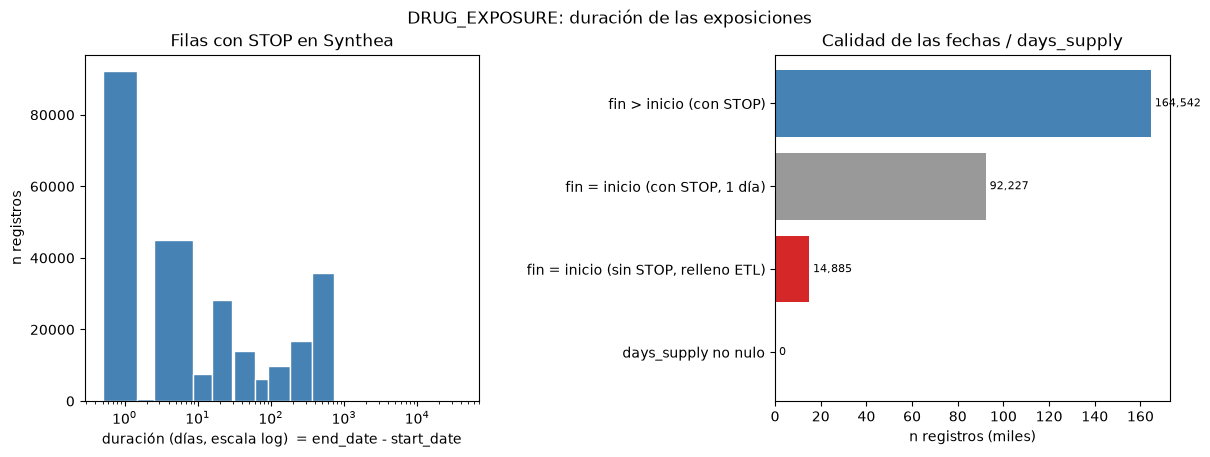

In [6]:
dur = con.execute("""
    SELECT date_diff('day', drug_exposure_start_date, drug_exposure_end_date) AS dias,
           verbatim_end_date IS NULL AS sin_stop,
           days_supply
    FROM drug_exposure
""").df()
print("days_supply no nulos:", int(dur["days_supply"].notna().sum()), "de", len(dur))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"wspace": 0.75})
con_stop = dur.loc[~dur["sin_stop"], "dias"].clip(lower=0)
bins = [0, 1, 2, 8, 15, 29, 31, 61, 91, 181, 366, 731, 1826, 3651, 40000]
ax[0].hist(con_stop + 0.5, bins=[b + 0.5 if b else 0.5 for b in bins], color="steelblue", edgecolor="white")
ax[0].set_xscale("log")
ax[0].set_xlabel("duración (días, escala log)  = end_date - start_date")
ax[0].set_ylabel("n registros")
ax[0].set_title("Filas con STOP en Synthea")
resumen = pd.Series({
    "fin > inicio (con STOP)": int((con_stop > 0).sum()),
    "fin = inicio (con STOP, 1 día)": int((con_stop == 0).sum()),
    "fin = inicio (sin STOP, relleno ETL)": int(dur["sin_stop"].sum()),
    "days_supply no nulo": int(dur["days_supply"].notna().sum()),
})
ax[1].barh(resumen.index[::-1], resumen.values[::-1], color=["orange", "#d62728", "#999", "steelblue"])
ax[1].set_title("Calidad de las fechas / days_supply")
ax[1].set_xlabel("n registros (miles)")
ax[1].xaxis.set_major_formatter(lambda x, pos: f"{x / 1000:,.0f}")
for i, v in enumerate(resumen.values[::-1]):
    ax[1].text(v, i, f" {v:,}", va="center", fontsize=8)
fig.suptitle("DRUG_EXPOSURE: duración de las exposiciones")
guardar(fig, "01_duracion_exposicion.png")
plt.show()

## Actividad 3 — Ingrediente exacto vs. descendientes

In [7]:
consulta("3.1")

CONSULTA 3.1 | ¿Cuántas personas tienen drug_concept_id = el INGREDIENTE exacto vs. cualquier descendiente (CONCEPT_ANCESTOR)?


,ingrediente,metodo,n_personas,n_registros
0,lisinopril,A) drug_concept_id = ingrediente (exacto),0,0
1,lisinopril,B) descendientes del ingrediente (concept_ance...,926,24334


In [8]:
consulta("3.2")

CONSULTA 3.2 | ¿Qué productos concretos (descendientes) aportan esos pacientes?


,drug_concept_id,producto,clase,niveles_desde_ingrediente,n_personas,n_registros
0,19080128,lisinopril 10 MG Oral Tablet,Clinical Drug,2,843,23679
1,19080129,lisinopril 20 MG Oral Tablet,Clinical Drug,2,68,605
2,1308251,lisinopril 5 MG Oral Tablet,Clinical Drug,2,21,21
3,974200,hydrochlorothiazide 12.5 MG / lisinopril 20 MG...,Clinical Drug,2,7,7
4,974199,hydrochlorothiazide 12.5 MG / lisinopril 10 MG...,Clinical Drug,2,6,6
5,1308221,lisinopril 40 MG Oral Tablet,Clinical Drug,2,5,5
6,1308250,lisinopril 2.5 MG Oral Tablet,Clinical Drug,2,5,5
7,974201,hydrochlorothiazide 25 MG / lisinopril 20 MG O...,Clinical Drug,2,5,5
8,19029027,lisinopril 30 MG Oral Tablet,Clinical Drug,2,1,1


## Actividad 4 — DRUG_ERA a mano (ventana de persistencia de 30 días)
Las tablas `results.exposicion_ingrediente`, `results.cobertura_ingrediente` y `results.drug_era_ingrediente` las creó `farmacoepi.sql` (consultas 4.1–4.3).

In [9]:
display(con.execute(
        "SELECT count(*) AS n_eras, count(DISTINCT person_id) AS n_personas, sum(gap_days) AS gap_days "
        "FROM results.drug_era_ingrediente").df())
display(consulta("4.4"))
display(consulta("4.5"))
consulta("4.7")

,n_eras,n_personas,gap_days
0,942,926,0.0


CONSULTA 4.4 | ¿Cómo se reparten las eras del ingrediente por duración? (con su nombre)


,ingrediente,duracion_era,n_eras,n_personas
0,lisinopril,a) <= 30 días,98,98
1,lisinopril,b) 31-90,4,4
2,lisinopril,c) 91-365,11,11
3,lisinopril,d) 1-5 años,126,126
4,lisinopril,e) > 5 años,703,703


CONSULTA 4.5 | ¿Existe una tabla DRUG_ERA derivada en la base con la que comparar?


,tabla_buscada,esquema,estado
0,condition_era,results,existe (creada por nosotros en este lab)
1,dose_era,-,NO existe
2,drug_era,results,existe (creada por nosotros en este lab)


CONSULTA 4.7 | ¿Coincide la era "a mano" del ingrediente (4.3) con la de la DRUG_ERA completa (4.6)?


,ingrediente,eras_4_3,eras_4_6,personas_4_3,personas_4_6
0,lisinopril,942,942,926,926


CONSULTA 0.1 | [CREA results.parametros] ¿Qué ingrediente, analitos y ventanas usaremos en todo el lab?


Figura guardada en /home/alecedillo/s13-omop-drug-measurement/figuras/05_drug_era.png


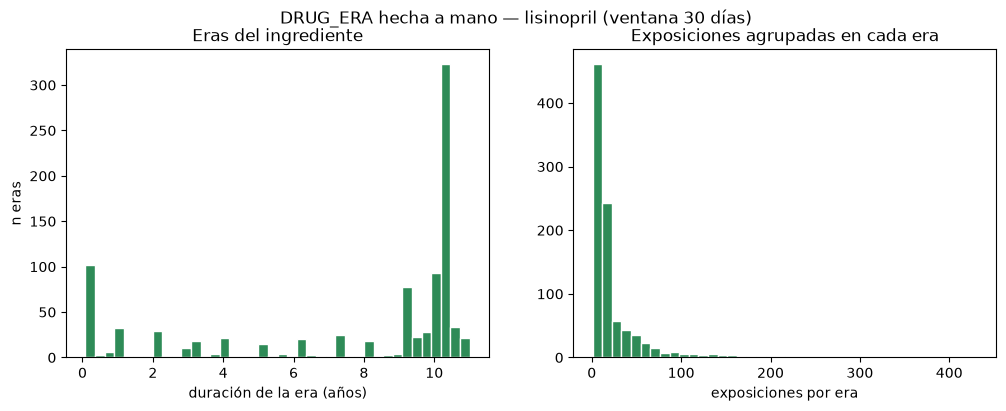

In [10]:
eras = con.execute("""
    SELECT date_diff('day', drug_era_start_date, drug_era_end_date) + 1 AS dias_era,
           drug_exposure_count
    FROM results.drug_era_ingrediente
""").df()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(eras["dias_era"] / 365.25, bins=40, color="seagreen", edgecolor="white")
ax[0].set_xlabel("duración de la era (años)"); ax[0].set_ylabel("n eras")
ax[0].set_title("Eras del ingrediente")
ax[1].hist(eras["drug_exposure_count"], bins=40, color="seagreen", edgecolor="white")
ax[1].set_xlabel("exposiciones por era"); ax[1].set_title("Exposiciones agrupadas en cada era")
nombre = consulta("0.1").loc[0, "ingrediente"]
fig.suptitle(f"DRUG_ERA hecha a mano — {nombre} (ventana 30 días)")
guardar(fig, "05_drug_era.png")
plt.show()

## Actividad 5 — PDC y MPR en el primer año
* **PDC** = días distintos cubiertos / días de la ventana (≤ 1).
* **MPR** = días suministrados / días de la ventana (puede ser > 1).

In [11]:
display(consulta("5.2"))
display(consulta("5.3"))
consulta("5.4")

CONSULTA 5.2 | ¿Cómo se distribuye el PDC entre los pacientes elegibles y qué % es adherente (PDC >= 0.8)?


,ingrediente,poblacion,n_personas,pdc_p10,pdc_p25,pdc_mediana,pdc_media,pct_adherentes_pdc_080
0,lisinopril,a) ventana >= 91 días,912,0.99,1.0,1.0,0.914,90.2
1,lisinopril,b) + criterio PQA (>= 2 recetas),301,1.00,1.0,1.0,0.984,97.3


CONSULTA 5.3 | ¿En cuántos pacientes el MPR supera 1 (y el PDC nunca)? ¿Por qué?


,n_personas_elegibles,n_mpr_mayor_1,mpr_maximo,pdc_maximo,mpr_media,pdc_media,pct_adherentes_mpr_080
0,912,821,2.014,1.0,1.018,0.914,90.4


CONSULTA 5.4 | ¿Cuántos pacientes quedan fuera de la elegibilidad y por qué?


,motivo,pdc_media,n_personas
0,a) ventana < 91 días (poco seguimiento),0.966,14
1,"b) elegible, pero solo 1 receta en el año (fue...",0.880,611
2,c) elegible también con criterio PQA,0.984,301


Figura guardada en /home/alecedillo/s13-omop-drug-measurement/figuras/02_pdc_mpr.png


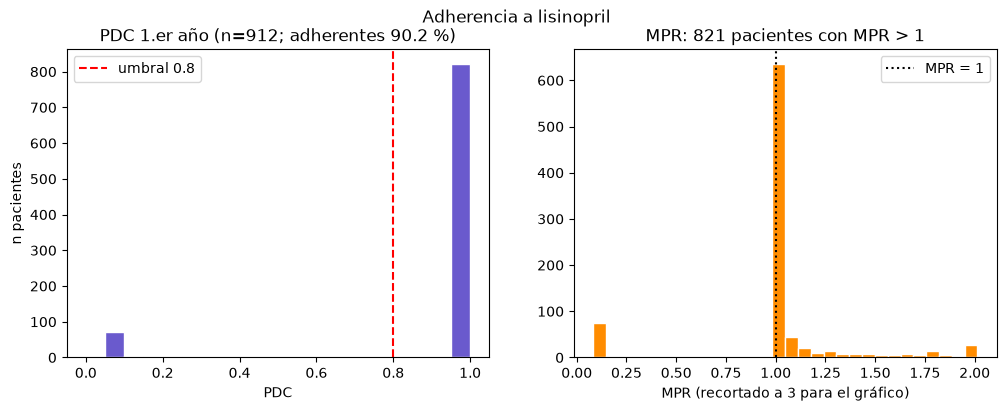

In [12]:
pdc = con.execute("SELECT pdc::DOUBLE AS pdc, mpr::DOUBLE AS mpr, elegible_pqa FROM results.pdc_ingrediente WHERE elegible").df()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(pdc["pdc"], bins=[i / 20 for i in range(21)], color="slateblue", edgecolor="white")
ax[0].axvline(0.8, color="red", ls="--", label="umbral 0.8")
ax[0].set_xlabel("PDC"); ax[0].set_ylabel("n pacientes"); ax[0].legend()
ax[0].set_title(f"PDC 1.er año (n={len(pdc)}; adherentes {100 * (pdc['pdc'] >= 0.8).mean():.1f} %)")
ax[1].hist(pdc["mpr"].clip(upper=3), bins=30, color="darkorange", edgecolor="white")
ax[1].axvline(1, color="black", ls=":", label="MPR = 1")
ax[1].set_xlabel("MPR (recortado a 3 para el gráfico)"); ax[1].legend()
ax[1].set_title(f"MPR: {int((pdc['mpr'] > 1).sum())} pacientes con MPR > 1")
fig.suptitle(f"Adherencia a {nombre}")
guardar(fig, "02_pdc_mpr.png")
plt.show()

## Actividad 6 — Caracterizar MEASUREMENT

In [13]:
consulta("6.1")

CONSULTA 6.1 | ¿Cuáles son los 15 analitos con más mediciones (y cuántos pacientes tienen cada uno)?


,measurement_concept_id,analito,n_mediciones,n_personas,n_unidades
0,43055141,Pain severity - 0-10 verbal numeric rating [Sc...,132560,5706,1
1,3012888,Diastolic blood pressure,80109,5706,1
2,3004249,Systolic blood pressure,80109,5706,1
3,3025315,Body weight,76445,5706,1
4,3027018,Heart rate,74894,5706,1
5,3024171,Respiratory rate,74894,5706,1
6,3036277,Body height,73247,5706,1
7,3038553,Body mass index (BMI) [Ratio],67737,5575,1
8,46236952,Glomerular filtration rate [Volume Rate/Area] ...,54481,1598,2
9,44786664,Weight difference [Mass difference] --pre dial...,50536,176,1


In [14]:
%%sql
SELECT count(*) AS n_mediciones,
       round(100.0 * count(*) FILTER (WHERE value_as_number IS NULL) / count(*), 2)        AS pct_valor_nulo,
       round(100.0 * count(*) FILTER (WHERE operator_concept_id IS NOT NULL) / count(*), 2) AS pct_con_operador,
       round(100.0 * count(*) FILTER (WHERE unit_concept_id = 0) / count(*), 2)             AS pct_unidad_0
FROM measurement

Running query in 'omop'

n_mediciones,pct_valor_nulo,pct_con_operador,pct_unidad_0
2195630,0.0,0.0,12.51


In [15]:
display(consulta("6.2"))
consulta("6.5")

CONSULTA 6.2 | ¿En qué unidades viene la glucosa (o el analito de parámetros)?


,analito,unidad_fuente,unit_concept_id,unidad,n_mediciones,n_personas
0,Glucose [Mass/volume] in Blood,mg/dL,8840,milligram per deciliter,48131,2526


CONSULTA 6.5 | ¿Qué unidades fuente se quedaron sin unit_concept_id (las 10 más frecuentes)?


,unidad_fuente,n_analitos,ejemplo_analito,n_mediciones
0,{score},1,Pain severity - 0-10 verbal numeric rating [Sc...,132560
1,U/L,5,Lactate dehydrogenase [Enzymatic activity/volu...,53211
2,mL/min/{1.73_m2},1,Glomerular filtration rate [Volume Rate/Area] ...,36899
3,{nominal},1,Specific gravity of Urine by Test strip,33854
4,kU/L,15,Walnut IgE Ab [Units/volume] in Serum,6210
5,{presence},7,Protein [Presence] in Urine by Test strip,5103
6,[pH],3,pH of Arterial blood,3241
7,{INR},1,INR in Platelet poor plasma by Coagulation assay,2563
8,{SG},1,Specific gravity of Urine by Test strip,729
9,m[IU]/L,1,Thyrotropin [Units/volume] in Serum or Plasma,208


## Actividad 7 — Normalizar unidades
* Caso **real**: temperatura en `Cel` y `[degF]`.
* Caso **simulado**: 30 % de las glucosas pasadas a mmol/L (÷ 18.016) y vueltas a mg/dL.

In [16]:
consulta("7.0")

CONSULTA 7.0 | Antes de convertir: ¿los valores de cada unidad tienen la magnitud que esperas de esa unidad?


,measurement_concept_id,analito,unidad_fuente,unidad,n_mediciones,minimo,mediana,maximo
0,3006923,Alanine aminotransferase [Enzymatic activity/v...,U/L,No matching concept,17285,0.0,35.60,60.0
1,3006923,Alanine aminotransferase [Enzymatic activity/v...,[iU]/L,international unit per liter,12,101.8,127.70,168.9
2,3035995,Alkaline phosphatase [Enzymatic activity/volum...,U/L,No matching concept,17285,20.0,79.60,140.0
3,3035995,Alkaline phosphatase [Enzymatic activity/volum...,[iU]/L,international unit per liter,12,35.4,77.95,114.5
4,3013721,Aspartate aminotransferase [Enzymatic activity...,U/L,No matching concept,17285,0.0,22.20,40.0
5,3013721,Aspartate aminotransferase [Enzymatic activity...,[iU]/L,international unit per liter,12,101.8,170.45,195.0
6,3020891,Body temperature,Cel,degree Celsius,6297,36.1,37.80,42.2
7,3020891,Body temperature,[degF],degree Fahrenheit,1,101.9,101.90,101.9
8,3019897,Erythrocyte [DistWidth] in Blood by Automated ...,fL,femtoliter,13900,39.0,42.50,46.0
9,3019897,Erythrocyte [DistWidth] in Blood by Automated ...,%,percent,4566,12.3,13.90,15.4


In [17]:
consulta("7.2")

CONSULTA 7.2 | [CREA results.measurement_normalizada] ¿Cuántas filas hay que convertir y cómo quedan (glucosa simulada + temperatura real)?


,caso,analito,unit_original,convertido,n_mediciones,n_personas,media_original,media_normalizada,unidad_final
0,glucosa (simulada),Glucose [Mass/volume] in Blood,mg/dL,False,33658,2489,88.20,88.20,mg/dL
1,glucosa (simulada),Glucose [Mass/volume] in Blood,mmol/L,True,14473,2251,4.90,88.25,mg/dL
2,temperatura (real),Body temperature,Cel,False,6297,3243,38.24,38.24,Cel
3,temperatura (real),Body temperature,[degF],True,1,1,101.90,38.80,Cel


Figura guardada en /home/alecedillo/s13-omop-drug-measurement/figuras/03_normalizacion_glucosa.png


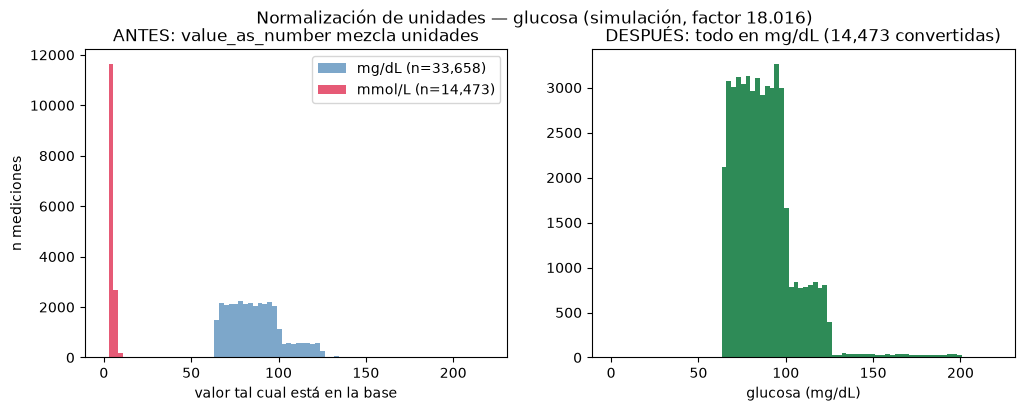

In [18]:
glu = con.execute("""
    SELECT value_original::DOUBLE AS antes, unit_original, value_as_number::DOUBLE AS despues
    FROM results.measurement_normalizada WHERE caso = 'glucosa (simulada)'
""").df()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for unidad, color in [("mg/dL", "steelblue"), ("mmol/L", "crimson")]:
    sub = glu[glu["unit_original"] == unidad]
    ax[0].hist(sub["antes"], bins=80, range=(0, 220), alpha=0.7, color=color, label=f"{unidad} (n={len(sub):,})")
ax[0].set_title("ANTES: value_as_number mezcla unidades")
ax[0].set_xlabel("valor tal cual está en la base"); ax[0].set_ylabel("n mediciones"); ax[0].legend()
ax[1].hist(glu["despues"], bins=80, range=(0, 220), color="seagreen")
ax[1].set_title(f"DESPUÉS: todo en mg/dL ({int((glu['unit_original'] == 'mmol/L').sum()):,} convertidas)")
ax[1].set_xlabel("glucosa (mg/dL)")
fig.suptitle("Normalización de unidades — glucosa (simulación, factor 18.016)")
guardar(fig, "03_normalizacion_glucosa.png")
plt.show()

## Actividad 8 — Rangos plausibles y valores centinela

In [19]:
rangos = consulta("8.1")
display(rangos)
display(consulta("8.2"))
consulta("8.3")

CONSULTA 8.1 | [CREA results.rangos_plausibles] ¿Qué rangos plausibles usaremos y de dónde salen?


,measurement_concept_id,analito,unidad,bajo,alto,bajo_alt,alto_alt,fuente
0,3038553,Body mass index (BMI) [Ratio],kg/m2,16.0,100.0,NaN,NaN,DQD v1.4.1 (extra: umbral pensado en adultos)
1,3025315,Body weight,kg,2.0,500.0,NaN,NaN,DQD v1.4.1 (kg)
2,3027018,Heart rate,/min,10.0,500.0,0.0,300.0,"DQD v1.4.1; alt. MIMIC-IV (0,300)"
3,3004249,Systolic blood pressure,mm[Hg],10.0,250.0,0.0,400.0,"DQD v1.4.1; alt. MIMIC-IV (0,400)"


CONSULTA 8.2 | ¿Cuántas mediciones (y personas) caen fuera del rango, separando niños y adultos?


,analito,grupo_edad,n_mediciones,n_bajo,n_alto,pct_fuera,n_personas_fuera,n_fuera_alt
0,Body mass index (BMI) [Ratio],< 18 años,13016,2925,0,22.47,634,0
1,Body mass index (BMI) [Ratio],>= 18 años,54721,0,0,0.00,0,0
2,Body weight,< 18 años,18733,0,0,0.00,0,0
3,Body weight,>= 18 años,57712,0,0,0.00,0,0
4,Heart rate,< 18 años,18509,0,0,0.00,0,0
5,Heart rate,>= 18 años,56385,0,0,0.00,0,0
6,Systolic blood pressure,< 18 años,18791,0,0,0.00,0,0
7,Systolic blood pressure,>= 18 años,61318,0,0,0.00,0,0


CONSULTA 8.3 | ¿Hay valores "centinela" (exactamente repetidos e imposibles, p. ej. 0, 999, 9999, -1)?


,analito,orden,valor,n_repeticiones,pct_del_analito,fuera_de_rango,parece_centinela
0,Body mass index (BMI) [Ratio],1,27.8,2948,4.35,False,False
1,Body mass index (BMI) [Ratio],2,27.7,2799,4.13,False,False
2,Body mass index (BMI) [Ratio],3,27.5,2651,3.91,False,False
3,Body mass index (BMI) [Ratio],4,30.1,2315,3.42,False,False
4,Body mass index (BMI) [Ratio],5,27.9,2260,3.34,False,False
5,Body weight,1,81.7,458,0.60,False,False
6,Body weight,2,93.0,450,0.59,False,False
7,Body weight,3,85.9,443,0.58,False,False
8,Body weight,4,72.7,379,0.50,False,False
9,Body weight,5,76.7,363,0.47,False,False


Figura guardada en /home/alecedillo/s13-omop-drug-measurement/figuras/04_rangos_plausibles.png


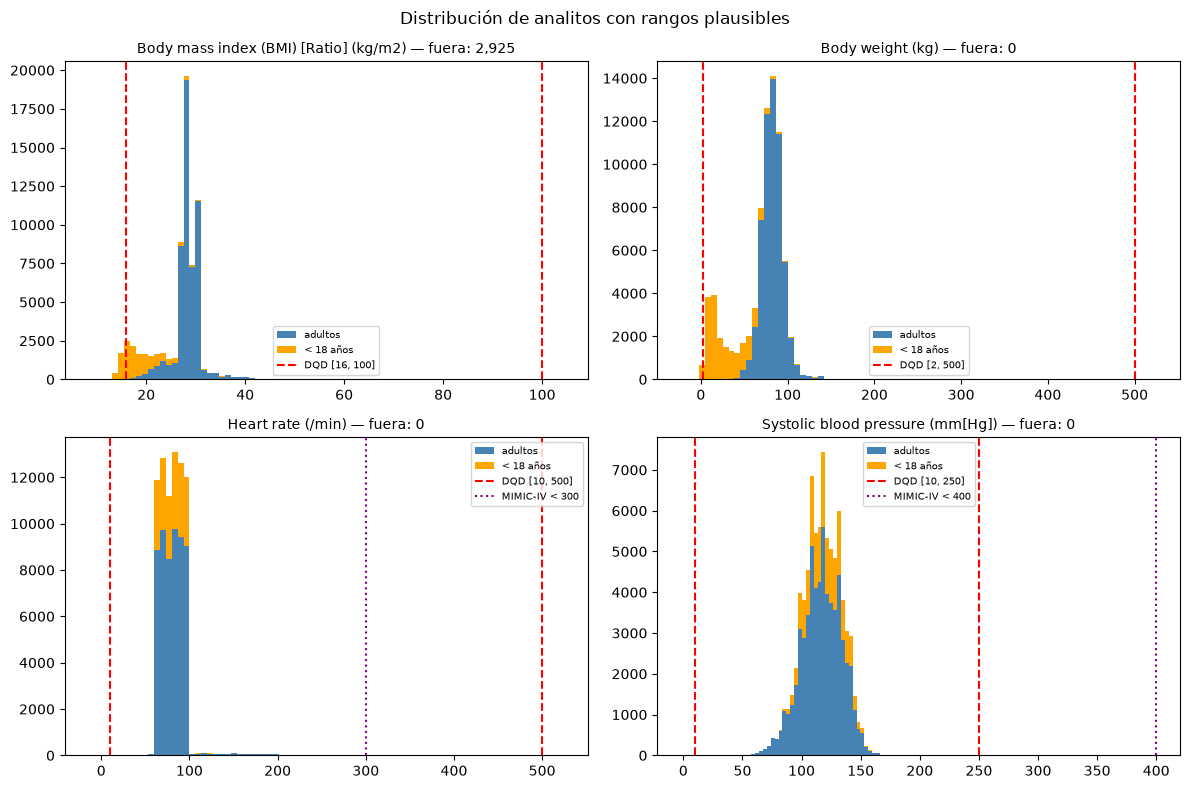

In [20]:
vals = con.execute("""
    SELECT c.concept_name AS analito, m.value_as_number::DOUBLE AS valor,
           (year(m.measurement_date) - p.year_of_birth) < 18 AS menor
    FROM measurement m
    JOIN results.rangos_plausibles r ON r.measurement_concept_id = m.measurement_concept_id
    JOIN concept c ON c.concept_id = m.measurement_concept_id
    JOIN person p  ON p.person_id = m.person_id
""").df()
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for ax, (_, r) in zip(axs.ravel(), rangos.iterrows()):
    sub = vals[vals["analito"] == r["analito"]]
    lo = min(sub["valor"].min(), r["bajo"]); hi = max(sub["valor"].max(), r["alto"])
    margen = (hi - lo) * 0.05
    ax.hist([sub.loc[~sub["menor"], "valor"], sub.loc[sub["menor"], "valor"]], bins=80,
            range=(lo - margen, hi + margen), stacked=True, color=["steelblue", "orange"],
            label=["adultos", "< 18 años"])
    ax.axvline(r["bajo"], color="red", ls="--", label=f"DQD [{r['bajo']:g}, {r['alto']:g}]")
    ax.axvline(r["alto"], color="red", ls="--")
    if pd.notna(r["alto_alt"]):
        ax.axvline(r["alto_alt"], color="purple", ls=":", label=f"MIMIC-IV < {r['alto_alt']:g}")
    fuera = ((sub["valor"] < r["bajo"]) | (sub["valor"] > r["alto"])).sum()
    ax.set_title(f"{r['analito']} ({r['unidad']}) — fuera: {fuera:,}", fontsize=10)
    ax.legend(fontsize=7)
fig.suptitle("Distribución de analitos con rangos plausibles")
fig.tight_layout()
guardar(fig, "04_rangos_plausibles.png")
plt.show()

In [21]:
consulta("8.4")

CONSULTA 8.4 | [CREA results.measurement_plausibilidad] Decisión: MARCAR (no borrar ni poner NULL). ¿Cuántas quedan marcadas?


,analito,n_mediciones,n_marcadas_fuera_rango,n_posible_centinela,n_marcadas_adultos
0,Body mass index (BMI) [Ratio],67737,2925,0,0
1,Body weight,76445,0,0,0
2,Heart rate,74894,0,0,0
3,Systolic blood pressure,80109,0,0,0


## Actividad 9 — ¿MEASUREMENT u OBSERVATION?
THEMIS: *Only records where the source value maps to a CONCEPT_ID in the 'Measurement' domain should be included in this table* (https://ohdsi.github.io/Themis/records_with_values.html).

In [22]:
display(consulta("9.1"))
display(consulta("9.2"))
consulta("9.3")

CONSULTA 9.1 | ¿De qué DOMINIO son los conceptos que acabaron en cada tabla clínica?


,tabla,dominio_concepto,n_registros,n_personas
0,condition_occurrence,Observation,104724,5706
1,condition_occurrence,Condition,95284,5620
2,condition_occurrence,(concepto 0),2859,2127
3,condition_occurrence,Measurement,1,1
4,drug_exposure,Drug,271654,5577
5,measurement,Measurement,2195630,5706


CONSULTA 9.2 | ¿Dónde quedaron el PESO, el TABAQUISMO y el "IMC 30+ obesidad" en nuestra base?


,tabla_actual,concept_id,concept_name,dominio_concepto,n_registros,n_personas
0,condition_occurrence,4060985,Body mass index 30+ - obesity,Condition,2687,2687
1,condition_occurrence,4256640,Body mass index 40+ - severely obese,Condition,27,27
2,measurement,3025315,Body weight,Measurement,76445,5706
3,measurement,3038553,Body mass index (BMI) [Ratio],Measurement,67737,5575
4,measurement,40762638,Body mass index (BMI) [Percentile] Per age and...,Measurement,14594,1858


CONSULTA 9.3 | ¿Qué concepto (y dominio) tendría "Tobacco smoking status" (LOINC 72166-2) y sus respuestas?


,concept_id,concept_name,vocabulary_id,concept_code,domain_id,standard_concept
0,43054909,Tobacco smoking status,LOINC,72166-2,Observation,S
1,4144272,Never smoked tobacco,SNOMED,266919005,Observation,-
2,42709996,Smokes tobacco daily,SNOMED,449868002,Observation,-
3,4310250,Ex-smoker,SNOMED,8517006,Observation,-


In [23]:
# Lee observations.csv de Synthea (ruta en la variable SYNTHEA_CSV o la de por defecto)
if (cf.SYNTHEA_CSV / "observations.csv").exists():
    display(consulta("9.4"))
else:
    print("No encuentro", cf.SYNTHEA_CSV / "observations.csv", "-> me salto la 9.4")

CONSULTA 9.4 | En el CSV ORIGINAL de Synthea, ¿cuántas respuestas de tabaquismo se perdieron al no tener tabla OBSERVATION?


,pregunta,respuesta,n_registros,n_pacientes_synthea
0,Tobacco smoking status,Never smoked tobacco (finding),55473,4551
1,Tobacco smoking status,Ex-smoker (finding),17198,1236
2,Tobacco smoking status,Smokes tobacco daily (finding),294,126


## Actividad 10 — Fecha índice y valor basal (±90 días)

In [24]:
display(consulta("10.2"))
consulta("10.3")

CONSULTA 10.2 | ¿Cuántos pacientes tienen valor basal (±90 y solo previo) y cómo es?


,ingrediente,analito_basal,n_personas,n_indice_en_periodo,n_con_basal_pm90,pct_con_basal_pm90,n_con_basal_previo,pct_con_basal_previo,mediana_basal_pm90,mediana_dias_a_indice
0,lisinopril,Systolic blood pressure,926,926,340,36.7,263,28.4,141.0,0.0


CONSULTA 10.3 | ¿Cómo se reparte la distancia (en días) entre la fecha índice y la medición basal elegida?


,distancia,n_personas
0,a) -90 a -31,14
1,b) -30 a -1,12
2,c) mismo día,237
3,d) +1 a +30,33
4,e) +31 a +90,44
5,z) sin basal en ±90,586


Figura guardada en /home/alecedillo/s13-omop-drug-measurement/figuras/06_valor_basal.png


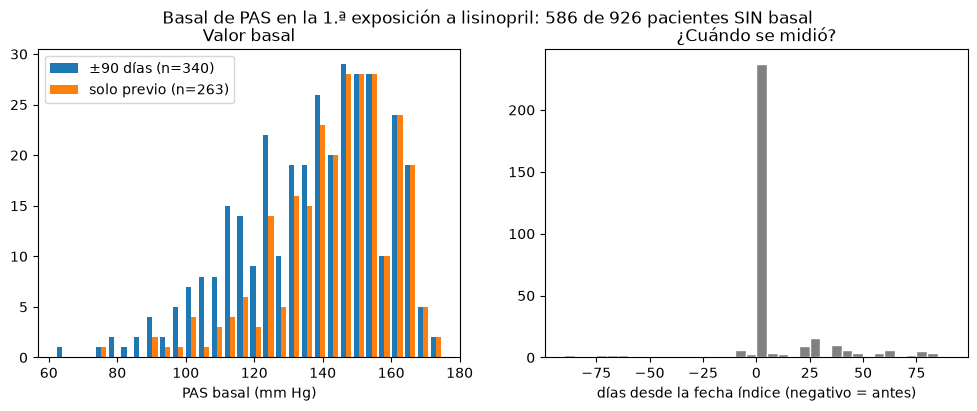

In [25]:
bas = con.execute("SELECT valor_pm90::DOUBLE AS pm90, valor_pre90::DOUBLE AS pre90, dif_pm90 FROM results.indice_basal").df()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist([bas["pm90"].dropna(), bas["pre90"].dropna()], bins=30,
           label=[f"±90 días (n={bas['pm90'].notna().sum()})", f"solo previo (n={bas['pre90'].notna().sum()})"])
ax[0].set_xlabel("PAS basal (mm Hg)"); ax[0].legend(); ax[0].set_title("Valor basal")
ax[1].hist(bas["dif_pm90"].dropna(), bins=36, range=(-90, 90), color="gray", edgecolor="white")
ax[1].set_xlabel("días desde la fecha índice (negativo = antes)"); ax[1].set_title("¿Cuándo se midió?")
sin = bas["pm90"].isna().sum()
fig.suptitle(f"Basal de PAS en la 1.ª exposición a {nombre}: {sin} de {len(bas)} pacientes SIN basal")
guardar(fig, "06_valor_basal.png")
plt.show()

## Extra — CONDITION_ERA

In [26]:
consulta("11.2")

CONSULTA 11.2 | (Extra) ¿Qué condiciones tienen más eras por persona (episodios repetidos)?


,condition_concept_id,condicion,n_eras,n_personas,eras_por_persona
0,4199788,Medication review due,29807,5706,5.22
1,4281516,Gingivitis,14157,4608,3.07
2,4053118,Full-time employment,12720,4470,2.85
3,4251306,Stress,13734,4468,3.07
4,4059634,Part-time employment,8669,3659,2.37
5,40481087,Viral sinusitis,5832,3615,1.61
6,4172829,Limited social contact,5385,3042,1.77
7,4309238,Social isolation,5342,3040,1.76
8,4090111,Gingival disease,4412,2706,1.63
9,4060985,Body mass index 30+ - obesity,2687,2687,1.00


In [27]:
con.close()
print("Conexión cerrada. Figuras en:", FIGURAS)
for f in sorted(FIGURAS.glob("*.png")):
    print(" -", f.name)

Conexión cerrada. Figuras en: /home/alecedillo/s13-omop-drug-measurement/figuras
 - 01_duracion_exposicion.png
 - 02_pdc_mpr.png
 - 03_normalizacion_glucosa.png
 - 04_rangos_plausibles.png
 - 05_drug_era.png
 - 06_valor_basal.png
